# Aircraft maintenance: experiments and results

**Main presentation notebook for Emanuele.** Runs the current core implementation,
saves checkpoints, evaluation data, training/execution timings and figures, and compares single-agent,
multi-agent reinforcement learning (MARL), and hierarchical reinforcement learning (HRL) controllers. Detailed teaching material remains in
`Comprehensive_RL_HRL_Maintenance_Tutorial.ipynb`; implementation details are in
the [updated code report](docs/reports/code_report_2026-10-26.pdf).

Run all cells in order. The configured runs are exploratory comparisons;
their rankings do not establish convergence or operational validity.

## 1. Setup and experiment settings

All registered methods are tested with seven aircraft, except MAXQ, which is
restricted to one aircraft. A separate one-aircraft panel compares **all methods**
with MAXQ under the same fleet size. Each trained method uses three initialization
seeds and the same held-out evaluation seeds. Settings and the core-source hash
are saved with every run. Increase `TRAIN_DAYS` for a longer study.

In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
import csv, gzip, hashlib, html, json, os, platform, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

PROJECT = next(p for p in (Path.cwd(), Path.cwd().parent)
               if (p / 'maintenance_tutorial_annotated_core.py').is_file())
sys.path.insert(0, str(PROJECT))
import maintenance_tutorial_annotated_core as core

TRAIN_DAYS = 1024
ROLLOUT_SIZE = 128
TRAIN_SEEDS = [0, 1000, 2000]
EVAL_SEEDS = list(range(10000, 10020))
HORIZON = 90
PANELS = {'fleet_7': core.Config(aircraft=7, horizon=HORIZON),
          'single_1': core.Config(aircraft=1, horizon=HORIZON)}
ALL_METHODS = tuple(core.ALL_LEARNED_METHODS)
METHODS = {panel: [m for m in ALL_METHODS if m != 'maxq' or cfg.aircraft == 1]
           for panel, cfg in PANELS.items()}
SOURCE_HASH = hashlib.sha256((PROJECT / core.__file__).read_bytes()).hexdigest()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
RUN = PROJECT / 'results' / ('presentation_' + RUN_ID)
for folder in ('checkpoints', 'training_logs', 'data', 'plots'):
    (RUN / folder).mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
try:
    SOURCE_COMMIT = subprocess.check_output(
        ['git', 'rev-parse', 'HEAD'], cwd=PROJECT, text=True).strip()
except (OSError, subprocess.CalledProcessError):
    SOURCE_COMMIT = None

def json_default(value):
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    raise TypeError(type(value).__name__)

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=json_default, allow_nan=False),
                    encoding='utf-8')

manifest = {'run_id': RUN_ID, 'core_sha256': SOURCE_HASH, 'source_commit': SOURCE_COMMIT,
            'observation_version': core.OBSERVATION_VERSION,
            'train_days_per_seed': TRAIN_DAYS, 'rollout_size': ROLLOUT_SIZE,
            'training_seeds': TRAIN_SEEDS, 'evaluation_seeds': EVAL_SEEDS,
            'panels': {p: asdict(c) for p, c in PANELS.items()}, 'methods': METHODS,
            'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                         'torch': str(torch.__version__), 'pandas': pd.__version__},
            'device': 'CPU; one Torch thread', 'status': 'running',
            'hardware': {'processor': platform.processor(), 'machine': platform.machine(),
                         'logical_cpu_count': os.cpu_count(), 'torch_threads': torch.get_num_threads(),
                         'system': platform.system(), 'release': platform.release()},
            'timing_protocol': {
                'clock': 'time.perf_counter; wall clock',
                'training': 'full core.train call including model/environment initialization and updates',
                'execution': 'core.evaluate per fixed-weight episode, including reset, policy, broker and simulator',
                'excluded_from_execution': 'warm-up, checkpoint loading, serialization, plots and learning',
                'evaluation_warmup': 'one complete episode at seed 9999 per controller, excluded from timing',
                'framework_warmup': 'one 16-day hrl_flat run before recorded training, discarded',
                'normalization': 'episode, simulated fleet day, and aircraft-day',
                'scope': 'sequential CPU measurements; not pure neural forward-pass latency or large-fleet extrapolation'},
            'interpretation': 'exploratory fixed-budget comparison; not convergence evidence'}
save_json(RUN / 'manifest.json', manifest)
display(pd.DataFrame([{'panel': p, 'aircraft': c.aircraft, 'horizon_days': c.horizon,
                       'learned_methods': len(METHODS[p]), 'days_per_training_seed': TRAIN_DAYS,
                       'training_seeds': len(TRAIN_SEEDS), 'evaluation_episodes_per_model': len(EVAL_SEEDS)}
                      for p, c in PANELS.items()]))
print('Results:', RUN.relative_to(PROJECT))
print('Core SHA-256:', SOURCE_HASH)

,panel,aircraft,horizon_days,learned_methods,days_per_training_seed,training_seeds,evaluation_episodes_per_model
0,fleet_7,7,90,17,1024,3,20
1,single_1,1,90,18,1024,3,20


Results: results\presentation_20261026T154304Z
Core SHA-256: a626792817b8f870a1ebe644f25cdf8783d97ed16eaff8652b7fc4060aec7628


## 2. Controller groups and comparison contract

MAPPO means multi-agent proximal policy optimization; DCMAC/DDMAC mean deep
centralized/decentralized multi-agent actor–critic. They share a replacement-request
broker, but differ in actor information, parameter sharing and learning updates.
The new aircraft hierarchy methods use a smaller 22-entry replacement catalog.
Original fleet controllers also learn resource selections.

`hrl_flat` and `planning_hierarchy` provide the closest flat-versus-staged comparison.
Scores across all methods also reflect different authority, decision timing and
objectives. Paired evaluation seeds give matched initial scenarios; policy-dependent
random-number consumption means they do not guarantee identical event histories.
The physical model remains synthetic, with the flight-condition upgrade pending.

In [2]:
MARL = ['mappo_aircraft', 'mappo_component', 'dcmac_aircraft',
        'ddmac_aircraft', 'dcmac_component', 'ddmac_component']
HRL = ['options', 'learned_options', 'concurrent_options', 'planning_hierarchy',
       'aggregate_targets', 'maxq', 'option_critic', 'hierarchical_vdn']
FAMILY = {m: ('MARL' if m in MARL else 'HRL' if m in HRL else
              'Catalog comparator' if m == 'hrl_flat' else 'Single-agent') for m in ALL_METHODS}
GROUPS = {'Original daily policies': ['flat', 'conditional', 'shared'],
          'Original fleet options': ['options', 'learned_options'],
          'MAPPO': ['mappo_aircraft', 'mappo_component'],
          'DCMAC / DDMAC': ['dcmac_aircraft', 'ddmac_aircraft', 'dcmac_component', 'ddmac_component'],
          'Aircraft planning policies': ['concurrent_options', 'planning_hierarchy', 'aggregate_targets', 'hrl_flat'],
          'Other hierarchies': ['maxq', 'option_critic', 'hierarchical_vdn']}
assert len(ALL_METHODS) == len(set(ALL_METHODS)) == 18
assert set(sum(GROUPS.values(), [])) == set(ALL_METHODS)
display(pd.DataFrame([{'method': m, 'family': FAMILY[m],
                       'fleet_7': m in METHODS['fleet_7'], 'single_1': True}
                      for m in ALL_METHODS]))

,method,family,fleet_7,single_1
0,flat,Single-agent,True,True
1,conditional,Single-agent,True,True
2,shared,Single-agent,True,True
3,options,HRL,True,True
4,learned_options,HRL,True,True
5,mappo_aircraft,MARL,True,True
6,mappo_component,MARL,True,True
7,dcmac_aircraft,MARL,True,True
8,ddmac_aircraft,MARL,True,True
9,dcmac_component,MARL,True,True


## 3. Train, save and evaluate

Each model is trained once per seed and saved before held-out evaluation. A
checkpoint reload must reproduce the first evaluation episode. Completed runs
are written immediately; failures stop execution instead of silently removing a
method from the comparison. Large checkpoints and full training logs stay local;
compact evaluation data and plots accompany the notebook on GitHub.

Wall-clock training includes initialization and learning. Execution is measured
per fixed-weight episode after an excluded warm-up; it includes reset, policy,
broker and physical simulation, but excludes loading, saving and plotting.
Execution timing is **end-to-end**, rather than pure neural inference latency.
The threshold rule has no training cost. All methods use the same CPU/thread
settings; hardware and timing boundaries are recorded in the manifest.

In [3]:
evaluation_rows, run_rows, curve_rows, timing_rows = [], [], [], []

def persist_tables():
    pd.DataFrame(evaluation_rows).to_csv(RUN / 'data/evaluation.csv', index=False)
    pd.DataFrame(run_rows).to_csv(RUN / 'data/training_runs.csv', index=False)
    pd.DataFrame(timing_rows).to_csv(RUN / 'data/execution_runs.csv', index=False)
    pd.DataFrame(curve_rows).to_csv(RUN / 'data/training_episodes.csv', index=False)
    save_json(RUN / 'progress.json', {'completed_training_runs': len(run_rows),
              'expected_training_runs': sum(map(len, METHODS.values())) * len(TRAIN_SEEDS),
              'latest': run_rows[-1] if run_rows else None})

def timed_evaluate(cfg, method, model=None, seeds=EVAL_SEEDS):
    if model is not None: model.eval()
    warmup_start = time.perf_counter()
    core.evaluate(cfg, method, model, seeds=[9999])
    warmup_seconds = time.perf_counter() - warmup_start
    records = []
    for seed in seeds:
        start = time.perf_counter()
        record = core.evaluate(cfg, method, model, seeds=[seed])[0]
        elapsed = time.perf_counter() - start
        records.append({**record, 'execution_seconds': elapsed})
    total = sum(r['execution_seconds'] for r in records)
    stats = {'execution_seconds': total, 'execution_episodes': len(records),
             'execution_seconds_per_episode': total / len(records),
             'execution_ms_per_simulated_day': 1000 * total / (len(records) * cfg.horizon),
             'execution_ms_per_aircraft_day': 1000 * total / (len(records) * cfg.horizon * cfg.aircraft),
             'execution_p50_episode_seconds': float(np.median([r['execution_seconds'] for r in records])),
             'execution_p95_episode_seconds': float(np.percentile([r['execution_seconds'] for r in records], 95)),
             'warmup_seconds_excluded': warmup_seconds}
    assert total > 0 and all(r['execution_seconds'] > 0 for r in records)
    return records, stats

# Warm library initialization before any recorded model; this model is discarded.
warmup_start = time.perf_counter()
_warm_model, _, _ = core.train(core.Config(aircraft=1, horizon=8), 'hrl_flat',
                              steps=16, seed=424242, rollout_size=8)
del _warm_model
manifest['framework_warmup_seconds_excluded'] = time.perf_counter() - warmup_start
save_json(RUN / 'manifest.json', manifest)

def run_panel(panel):
    cfg = PANELS[panel]
    baseline_records, baseline_timing = timed_evaluate(cfg, 'threshold')
    for record in baseline_records:
        evaluation_rows.append({'panel': panel, 'method': 'threshold',
                                 'training_seed': -1, 'family': 'Fixed rule', **record})
    timing_rows.append({'panel': panel, 'method': 'threshold', 'training_seed': -1,
                        'training_seconds': 0., 'training_ms_per_simulated_day': 0.,
                        'training_ms_per_aircraft_day': 0., **baseline_timing})
    persist_tables()
    for method in METHODS[panel]:
        for seed in TRAIN_SEEDS:
            key = f'{panel}__{method}__seed{seed}'
            start = time.perf_counter()
            model, logs, days = core.train(cfg, method, steps=TRAIN_DAYS,
                                           seed=seed, rollout_size=ROLLOUT_SIZE)
            seconds = time.perf_counter() - start
            assert days == TRAIN_DAYS, (method, days)
            assert all(torch.isfinite(p).all() for p in model.parameters())
            checkpoint = RUN / 'checkpoints' / (key + '.pt')
            torch.save({'state_dict': model.state_dict(), 'config': asdict(cfg),
                        'method': method, 'training_seed': seed, 'simulated_days': days,
                        'observation_version': core.OBSERVATION_VERSION,
                        'core_sha256': SOURCE_HASH}, checkpoint)
            with gzip.open(RUN / 'training_logs' / (key + '.json.gz'), 'wt', encoding='utf-8') as handle:
                json.dump(logs, handle, default=json_default, allow_nan=False)
            evaluation, execution_timing = timed_evaluate(cfg, method, model)
            loaded_cfg, loaded_method, restored = core.load_checkpoint(checkpoint)
            assert loaded_cfg == cfg and loaded_method == method
            reference = {k: v for k, v in evaluation[0].items() if k != 'execution_seconds'}
            assert core.evaluate(cfg, method, restored, seeds=EVAL_SEEDS[:1])[0] == reference
            for record in evaluation:
                evaluation_rows.append({'panel': panel, 'method': method,
                                         'training_seed': seed, 'family': FAMILY[method], **record})
            for record in logs:
                if 'return' in record and record.get('record_type', 'episode') == 'episode':
                    curve_rows.append({'panel': panel, 'method': method, 'training_seed': seed,
                                        'simulated_days': record['simulated_days'],
                                        'episode_return': record['return']})
            run_record = {'panel': panel, 'method': method, 'training_seed': seed,
                          'simulated_days': days, 'training_seconds': seconds,
                          'training_ms_per_simulated_day': 1000 * seconds / days,
                          'training_ms_per_aircraft_day': 1000 * seconds / (days * cfg.aircraft),
                          'parameters': sum(p.numel() for p in model.parameters()),
                          'checkpoint': checkpoint.relative_to(RUN).as_posix(),
                          'core_sha256': SOURCE_HASH, 'reload_verified': True, **execution_timing}
            run_rows.append(run_record)
            timing_rows.append(run_record)
            persist_tables()
            print(f"{panel}: {method}, seed {seed}: train {seconds:.2f}s; "
                  f"execute {execution_timing['execution_seconds_per_episode']*1000:.1f}ms/episode; saved", flush=True)

run_panel('fleet_7')

fleet_7: flat, seed 0: train 6.00s; execute 502.4ms/episode; saved


fleet_7: flat, seed 1000: train 6.82s; execute 508.3ms/episode; saved


fleet_7: flat, seed 2000: train 6.63s; execute 559.8ms/episode; saved


fleet_7: conditional, seed 0: train 7.03s; execute 538.6ms/episode; saved


fleet_7: conditional, seed 1000: train 7.01s; execute 598.0ms/episode; saved


...

fleet_7: hierarchical_vdn, seed 1000: train 7.97s; execute 396.9ms/episode; saved


fleet_7: hierarchical_vdn, seed 2000: train 7.09s; execute 393.6ms/episode; saved


fleet_7: hrl_flat, seed 0: train 4.74s; execute 332.9ms/episode; saved


fleet_7: hrl_flat, seed 1000: train 4.70s; execute 308.9ms/episode; saved


fleet_7: hrl_flat, seed 2000: train 5.03s; execute 391.7ms/episode; saved


### One-aircraft comparison including MAXQ

This panel uses the same training budget, evaluation seeds and horizon for every
method. It is reported separately: single-aircraft performance is not a fleet
scalability result.

In [4]:
run_panel('single_1')

single_1: flat, seed 0: train 3.40s; execute 252.1ms/episode; saved


single_1: flat, seed 1000: train 3.47s; execute 253.5ms/episode; saved


single_1: flat, seed 2000: train 3.40s; execute 256.5ms/episode; saved


single_1: conditional, seed 0: train 3.54s; execute 236.7ms/episode; saved


single_1: conditional, seed 1000: train 3.07s; execute 271.2ms/episode; saved


...

single_1: hierarchical_vdn, seed 1000: train 2.64s; execute 124.5ms/episode; saved


single_1: hierarchical_vdn, seed 2000: train 2.62s; execute 122.6ms/episode; saved


single_1: hrl_flat, seed 0: train 2.07s; execute 292.0ms/episode; saved


single_1: hrl_flat, seed 1000: train 2.50s; execute 247.6ms/episode; saved


single_1: hrl_flat, seed 2000: train 3.38s; execute 246.2ms/episode; saved


## 4. Held-out results

Rank by mean **environment return**, then inspect availability, cost and failures.
Return is the simulator's composite objective, not a safety certificate. Mean and
standard deviation (SD) below are computed across training seeds after averaging each
seed's evaluation episodes. The threshold rule has no training-seed variation;
its zero error bar does not mean zero environmental uncertainty.

In [5]:
evaluation = pd.DataFrame(evaluation_rows)
runs = pd.DataFrame(run_rows)
curves = pd.DataFrame(curve_rows)
execution_runs = pd.DataFrame(timing_rows)
expected = sum((len(methods) * len(TRAIN_SEEDS) + 1) * len(EVAL_SEEDS)
               for methods in METHODS.values())
assert len(evaluation) == expected
assert not evaluation.duplicated(['panel', 'method', 'training_seed', 'seed']).any()
assert np.isfinite(evaluation[['return', 'cost', 'availability', 'flight_failures']]).all().all()
assert evaluation['availability'].between(0, 1).all()
assert runs['reload_verified'].all()
assert evaluation['execution_seconds'].gt(0).all()
assert execution_runs.execution_episodes.eq(len(EVAL_SEEDS)).all()
for panel, cfg in PANELS.items():
    mask = evaluation.panel.eq(panel)
    evaluation.loc[mask, 'cost_per_aircraft_day'] = evaluation.loc[mask, 'cost'] / (cfg.aircraft * cfg.horizon)
metrics = ['return', 'availability', 'cost_per_aircraft_day', 'flight_failures',
           'rejections', 'replacements']
seed_means = evaluation.groupby(['panel', 'method', 'training_seed'])[metrics].mean().reset_index()
summary = seed_means.groupby(['panel', 'method'])[metrics].agg(['mean', 'std'])
summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
summary = summary.reset_index().fillna(0)
timing = execution_runs.groupby(['panel', 'method'])[['training_seconds', 'parameters', 'execution_seconds_per_episode', 'execution_ms_per_simulated_day', 'execution_ms_per_aircraft_day']].mean().reset_index()
summary = summary.merge(timing, on=['panel', 'method'], how='left')
summary['family'] = summary.method.map({**FAMILY, 'threshold': 'Fixed rule'})
summary['rank_by_return'] = summary.groupby('panel').return_mean.rank(method='min', ascending=False).astype(int)
summary = summary.sort_values(['panel', 'rank_by_return', 'method'])
summary.to_csv(RUN / 'data/summary.csv', index=False)
seed_means.to_csv(RUN / 'data/seed_means.csv', index=False)
evaluation.to_csv(RUN / 'data/evaluation.csv', index=False)

def show_results(panel):
    table = summary[summary.panel.eq(panel)][['rank_by_return', 'method', 'family',
        'return_mean', 'return_std', 'availability_mean', 'cost_per_aircraft_day_mean',
        'flight_failures_mean', 'training_seconds', 'execution_seconds_per_episode']].copy()
    display(Markdown(f'### {panel}: ranked evaluation results'))
    display(table.round(3).reset_index(drop=True))

show_results('fleet_7')
show_results('single_1')

### fleet_7: ranked evaluation results

,rank_by_return,method,family,return_mean,return_std,availability_mean,cost_per_aircraft_day_mean,flight_failures_mean,training_seconds,execution_seconds_per_episode
0,1,hierarchical_vdn,HRL,89.834,0.004,0.999,0.007,0.0,7.686,0.403
1,2,conditional,Single-agent,89.812,0.013,0.999,0.010,0.0,7.148,0.564
2,3,flat,Single-agent,77.931,20.508,0.951,0.854,0.0,6.481,0.523
3,4,learned_options,HRL,66.106,0.458,0.856,1.215,0.0,3.598,0.298
4,5,shared,Single-agent,65.278,21.282,0.904,1.783,0.0,7.015,0.549
5,6,threshold,Fixed rule,60.678,0.000,0.815,1.410,0.0,0.000,0.238
6,7,options,HRL,51.139,9.003,0.756,1.876,0.0,3.142,0.292
7,8,option_critic,HRL,48.337,3.829,0.714,1.772,0.0,11.952,0.522
8,9,aggregate_targets,HRL,48.222,2.469,0.714,1.785,0.0,7.116,0.440
9,10,concurrent_options,HRL,48.191,0.000,0.714,1.788,0.0,4.396,0.294


### single_1: ranked evaluation results

,rank_by_return,method,family,return_mean,return_std,availability_mean,cost_per_aircraft_day_mean,flight_failures_mean,training_seconds,execution_seconds_per_episode
0,1,aggregate_targets,HRL,90.000,0.000,1.000,0.000,0.0,3.402,0.270
1,1,concurrent_options,HRL,90.000,0.000,1.000,0.000,0.0,1.225,0.113
2,1,conditional,Single-agent,90.000,0.000,1.000,0.000,0.0,3.382,0.260
3,1,dcmac_aircraft,MARL,90.000,0.000,1.000,0.000,0.0,4.429,0.102
4,1,dcmac_component,MARL,90.000,0.000,1.000,0.000,0.0,4.315,0.120
5,1,ddmac_aircraft,MARL,90.000,0.000,1.000,0.000,0.0,4.278,0.105
6,1,ddmac_component,MARL,90.000,0.000,1.000,0.000,0.0,6.743,0.129
7,1,flat,Single-agent,90.000,0.000,1.000,0.000,0.0,3.424,0.254
8,1,hierarchical_vdn,HRL,90.000,0.000,1.000,0.000,0.0,2.662,0.120
9,1,hrl_flat,Catalog comparator,90.000,0.000,1.000,0.000,0.0,2.650,0.262


## 5. Saved plots

Error bars show variation between trained seeds. Training curves use completed
episode returns, smoothed over five episodes within each seed. They measure
training behavior, whereas the ranked tables use held-out deterministic evaluation.

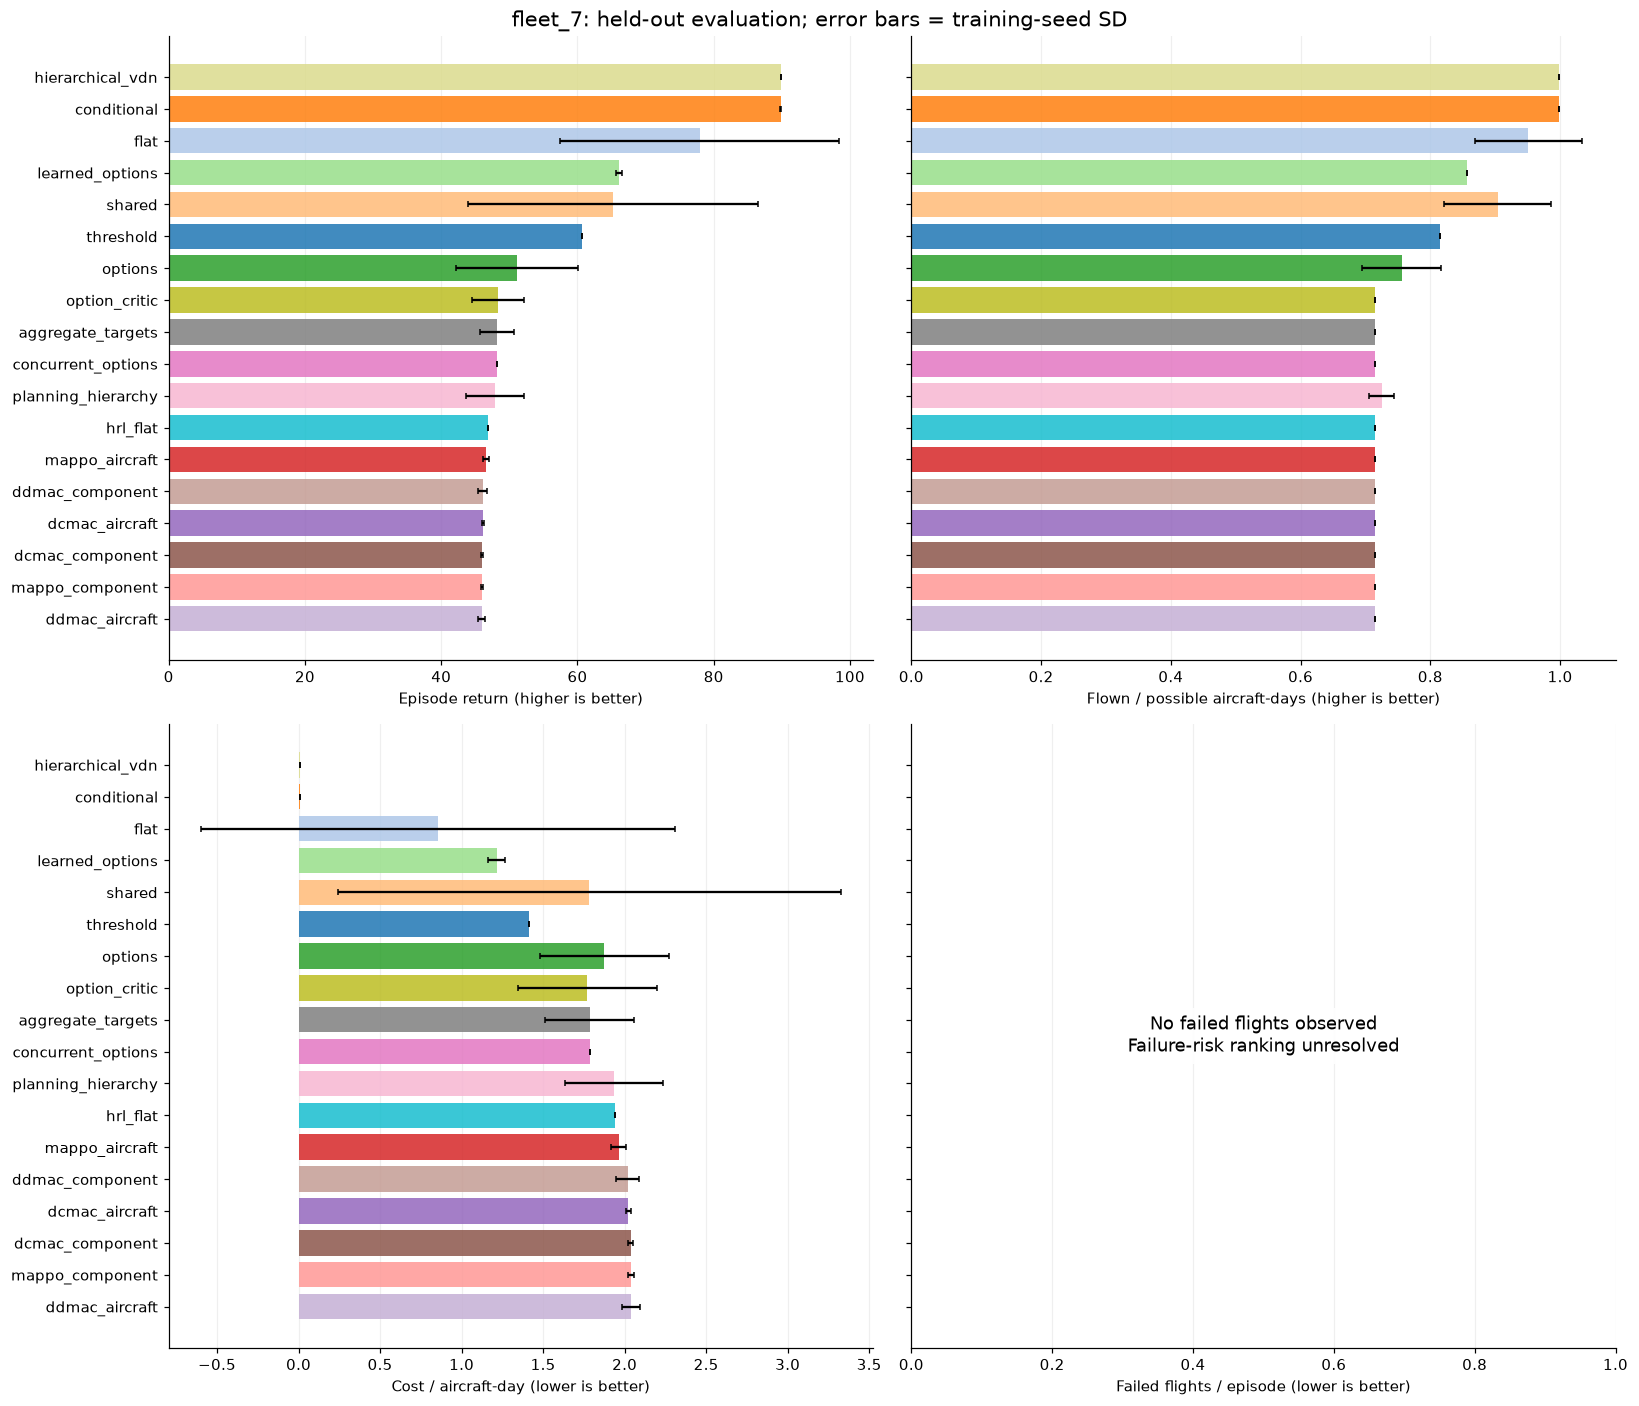

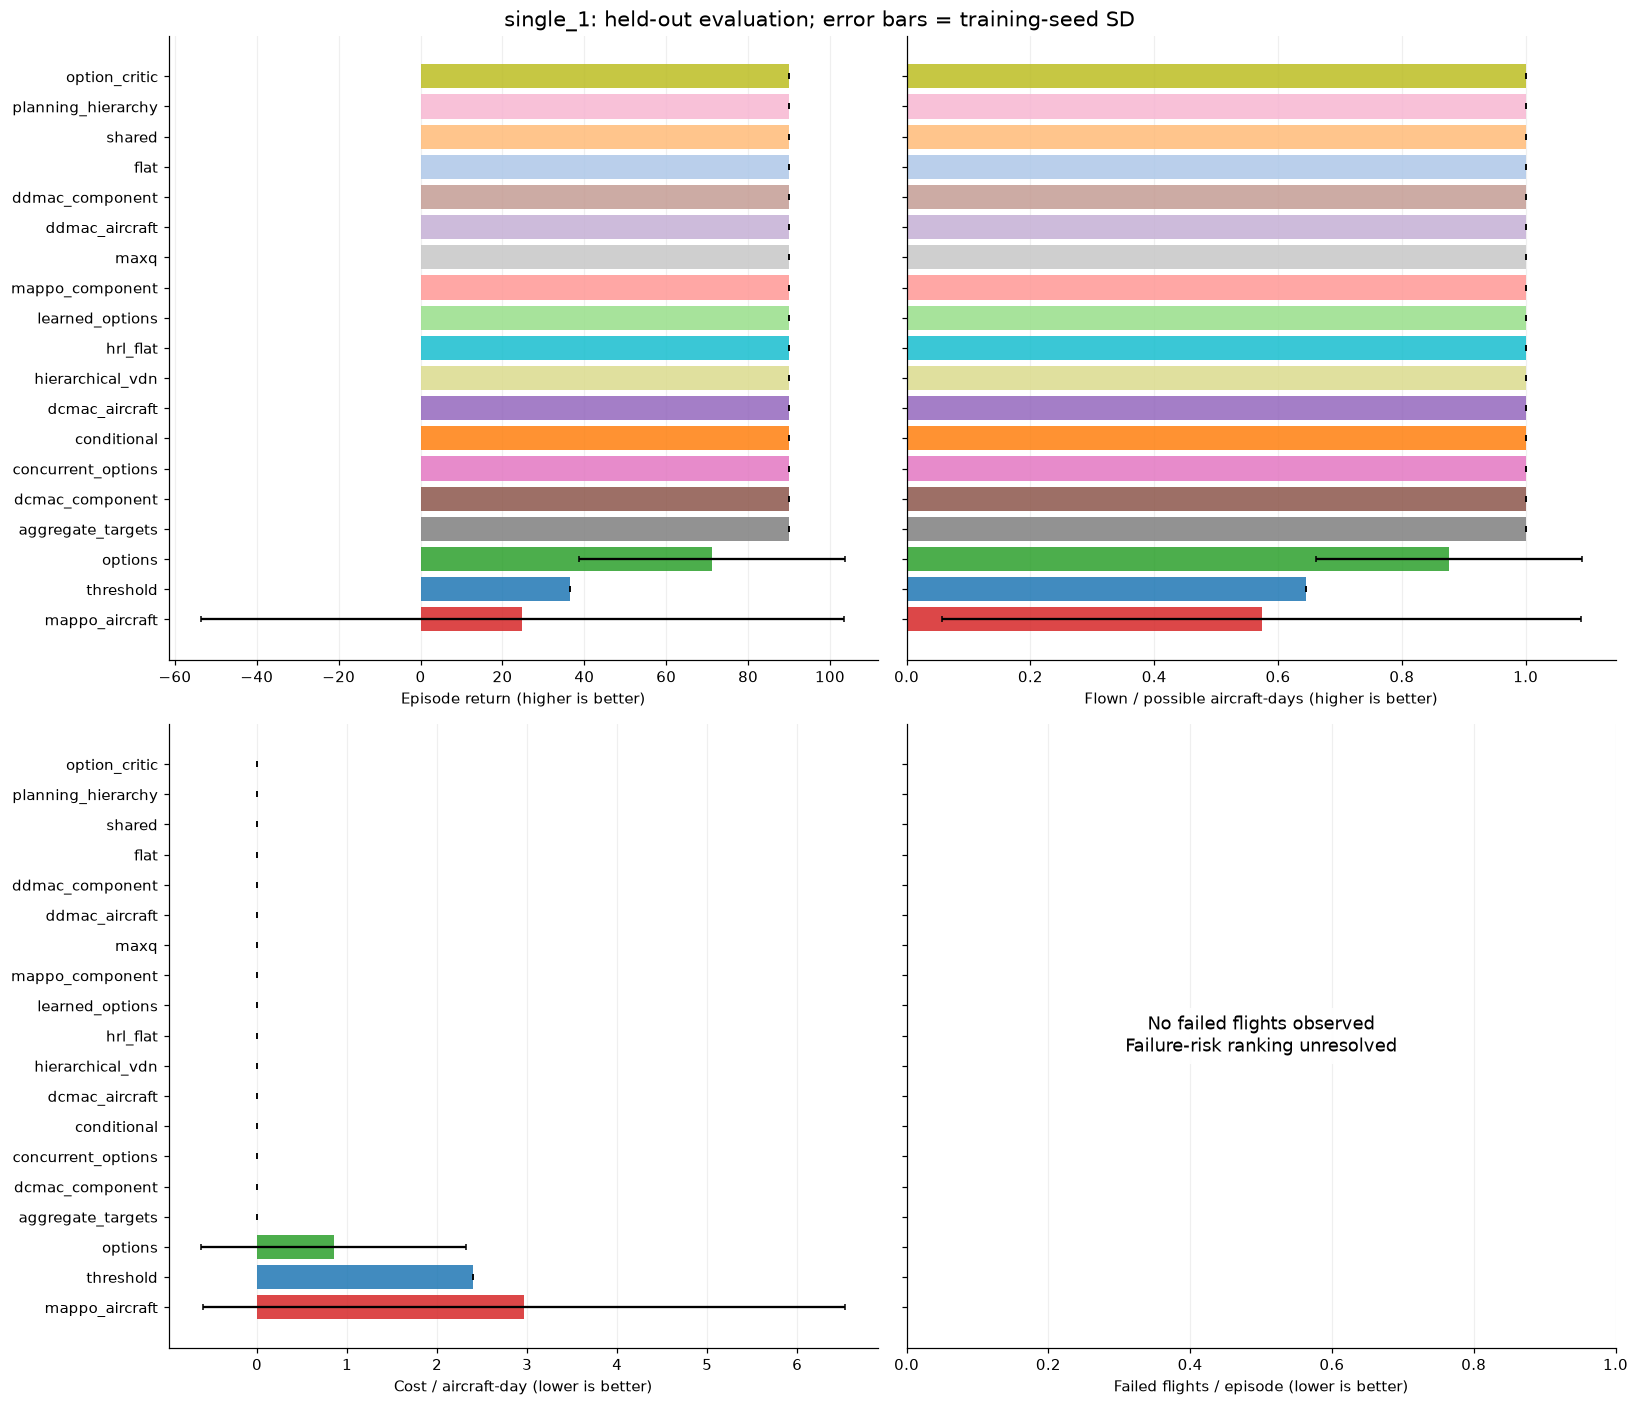

In [6]:
COLORS = {m: plt.get_cmap('tab20')(i) for i, m in enumerate(['threshold', *ALL_METHODS])}

def save_figure(fig, name):
    fig.savefig(RUN / 'plots' / (name + '.png'), bbox_inches='tight')
    fig.savefig(RUN / 'plots' / (name + '.svg'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

def comparison_plot(panel):
    data = summary[summary.panel.eq(panel)].sort_values('return_mean')
    fig, axes = plt.subplots(2, 2, figsize=(15, 13), sharey=True)
    selections = [('return', 'Episode return (higher is better)'),
                  ('availability', 'Flown / possible aircraft-days (higher is better)'),
                  ('cost_per_aircraft_day', 'Cost / aircraft-day (lower is better)'),
                  ('flight_failures', 'Failed flights / episode (lower is better)')]
    for ax, (metric, label) in zip(axes.flat, selections):
        ax.barh(data.method, data[metric + '_mean'], xerr=data[metric + '_std'],
                color=[COLORS[m] for m in data.method], alpha=.85, capsize=2)
        if metric == 'flight_failures' and np.allclose(data[metric + '_mean'], 0):
            ax.set_xlim(0, 1)
            ax.text(.5, .5, 'No failed flights observed\nFailure-risk ranking unresolved',
                    transform=ax.transAxes, ha='center', va='center', fontsize=12,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .9})
        ax.set_xlabel(label)
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle(f'{panel}: held-out evaluation; error bars = training-seed SD', fontsize=14)
    fig.tight_layout()
    save_figure(fig, panel + '_comparison')

comparison_plot('fleet_7')
comparison_plot('single_1')

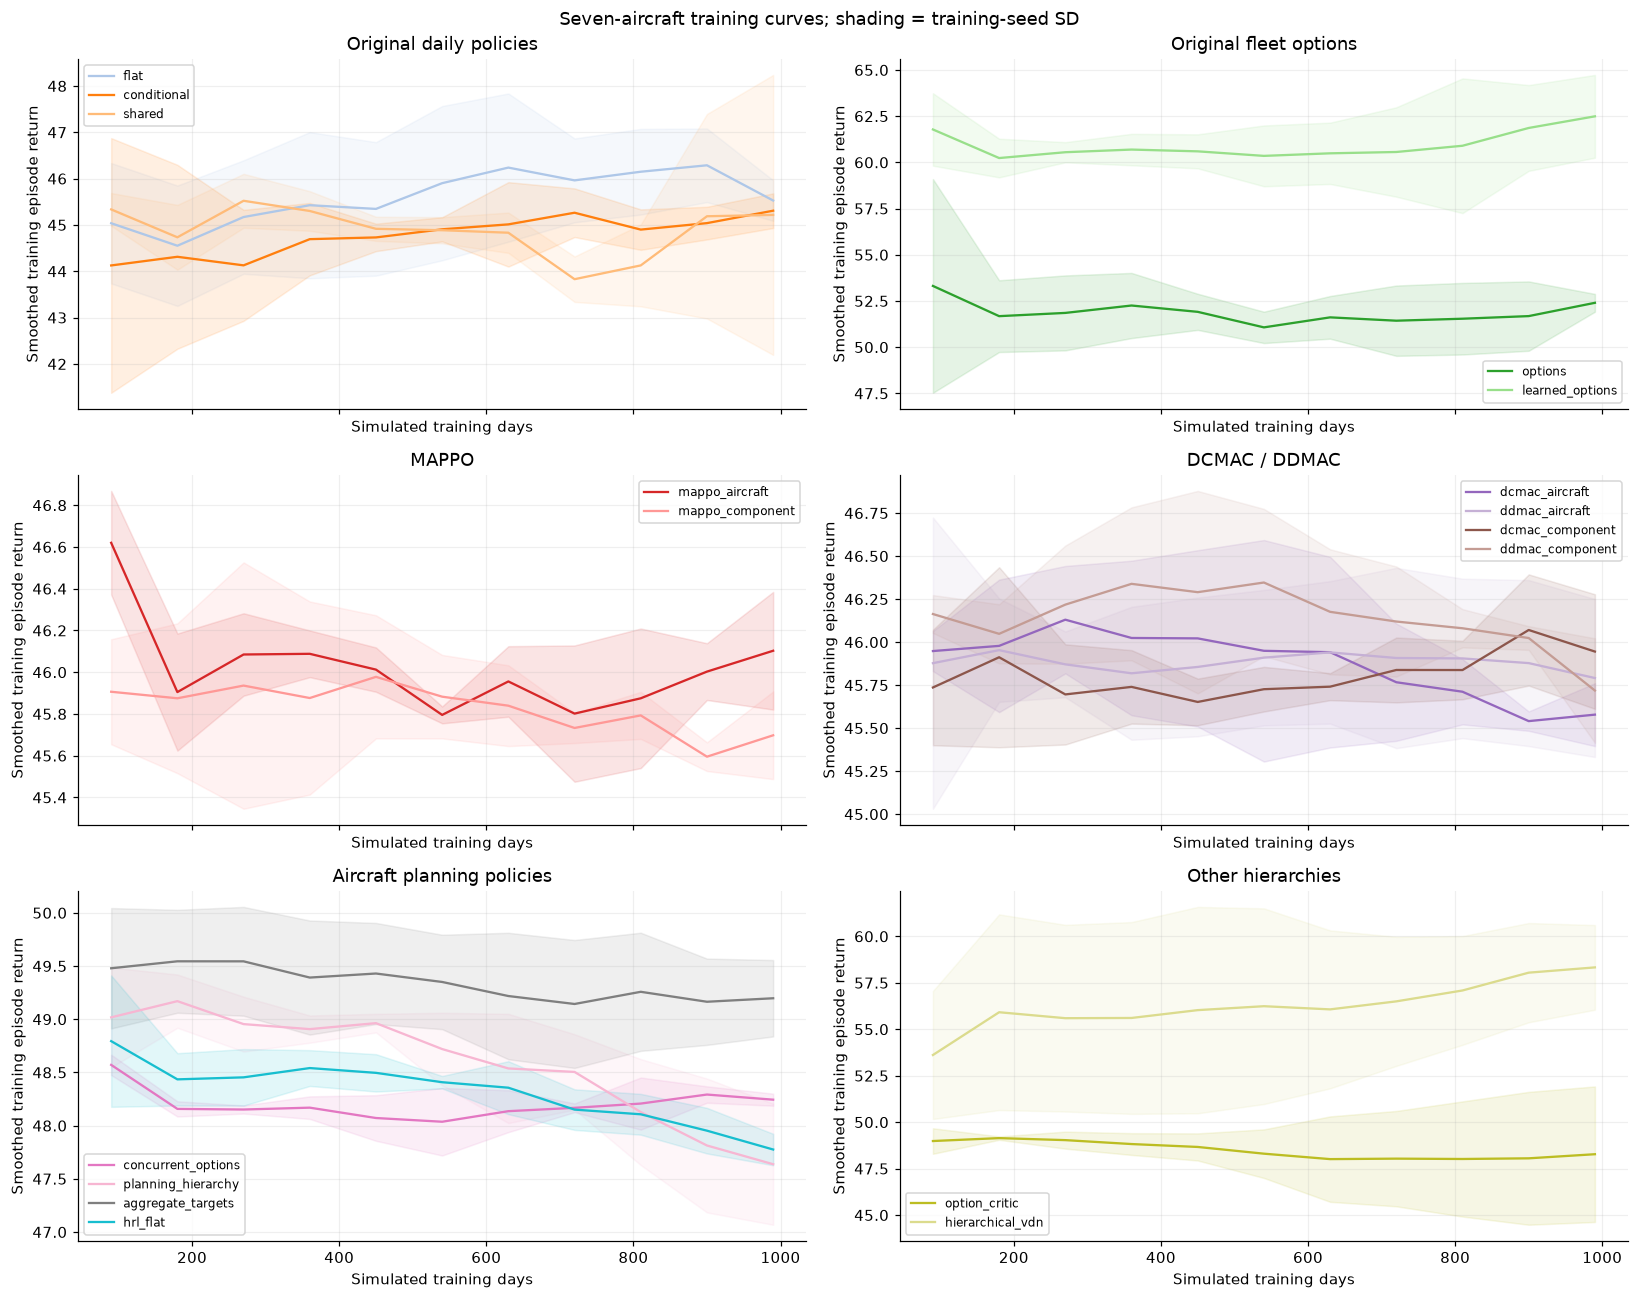

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
for ax, (group, methods) in zip(axes.flat, GROUPS.items()):
    for method in methods:
        data = curves[curves.panel.eq('fleet_7') & curves.method.eq(method)].copy()
        if data.empty: continue
        data['smoothed'] = data.groupby('training_seed').episode_return.transform(
            lambda values: values.rolling(5, min_periods=1).mean())
        # Aggregate by within-seed completed-episode index; use actual mean elapsed days on x.
        data['episode_index'] = data.groupby('training_seed').cumcount()
        points = data.groupby('episode_index').agg(days=('simulated_days', 'mean'),
                    mean=('smoothed', 'mean'), std=('smoothed', 'std')).fillna(0)
        ax.plot(points.days, points['mean'], label=method, color=COLORS[method])
        ax.fill_between(points.days, points['mean'] - points['std'],
                         points['mean'] + points['std'], color=COLORS[method], alpha=.12)
    ax.set_title(group)
    ax.set_xlabel('Simulated training days')
    ax.set_ylabel('Smoothed training episode return')
    ax.grid(alpha=.2)
    if ax.lines: ax.legend(fontsize=8)
fig.suptitle('Seven-aircraft training curves; shading = training-seed SD')
fig.tight_layout()
save_figure(fig, 'fleet_7_training_curves')

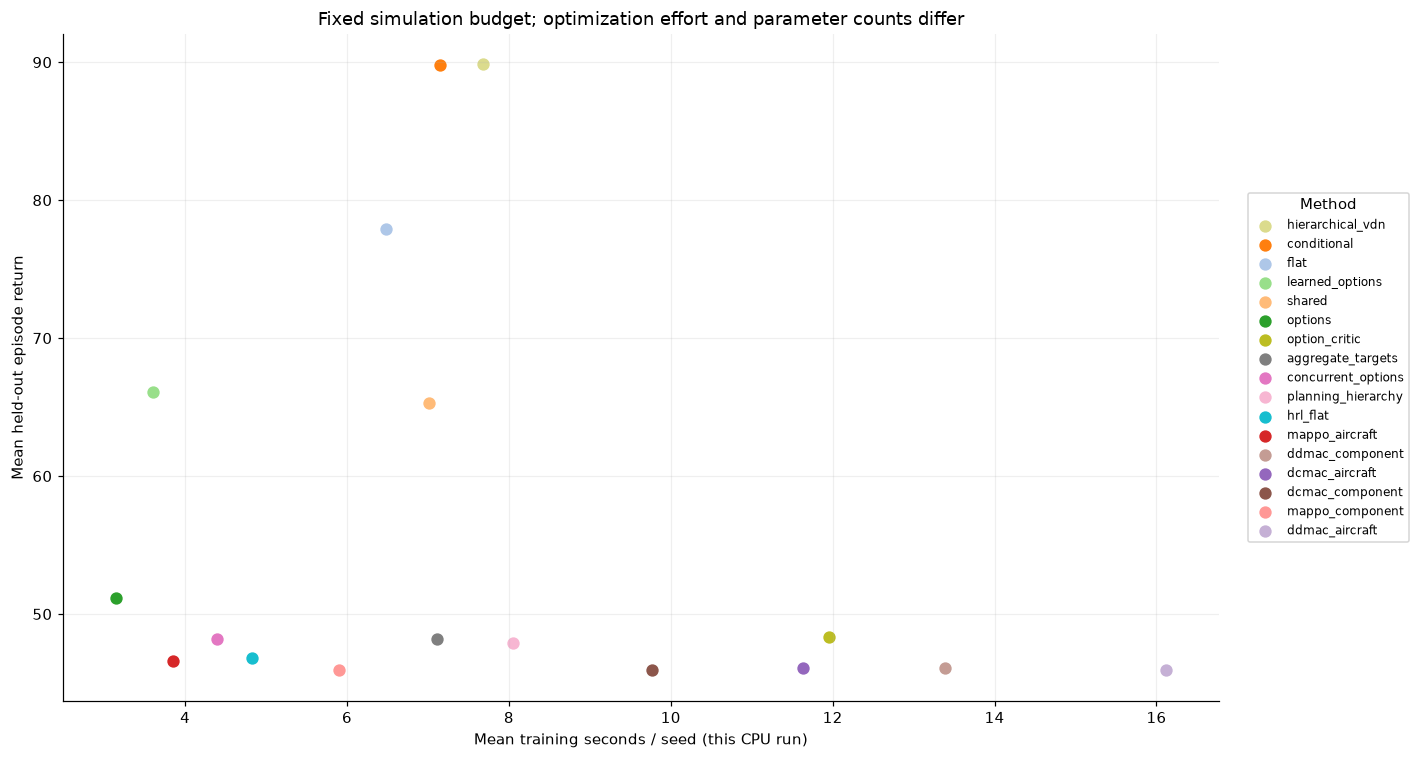

### Aircraft catalog methods relative to `hrl_flat`

,mean_delta_return,std_between_seed_pairs
method,,
planning_hierarchy,1.062,4.303
aggregate_targets,1.397,2.473
concurrent_options,1.366,0.008


Only planning_hierarchy is closely matched in authority and decision timing; all parameter counts differ.


In [8]:
fig, ax = plt.subplots(figsize=(13, 7))
data = summary[summary.panel.eq('fleet_7') & summary.method.ne('threshold')]
for row in data.itertuples():
    ax.scatter(row.training_seconds, row.return_mean, color=COLORS[row.method], s=50, label=row.method)
ax.set_xlabel('Mean training seconds / seed (this CPU run)')
ax.set_ylabel('Mean held-out episode return')
ax.set_title('Fixed simulation budget; optimization effort and parameter counts differ')
ax.grid(alpha=.2)
ax.legend(loc='center left', bbox_to_anchor=(1.02, .5), fontsize=8, title='Method')
fig.tight_layout()
save_figure(fig, 'fleet_7_return_vs_training_time')

matched = seed_means[seed_means.panel.eq('fleet_7')].pivot(
    index='training_seed', columns='method', values='return')
comparison_methods = ['planning_hierarchy', 'aggregate_targets', 'concurrent_options']
deltas = matched[comparison_methods].sub(matched['hrl_flat'], axis=0).dropna()
delta_summary = pd.DataFrame({'mean_delta_return': deltas.mean(),
                              'std_between_seed_pairs': deltas.std()})
delta_summary.index.name = 'method'
delta_summary.to_csv(RUN / 'data/catalog_comparison.csv')
display(Markdown('### Aircraft catalog methods relative to `hrl_flat`'))
display(delta_summary.round(3))
print('Only planning_hierarchy is closely matched in authority and decision timing; all parameter counts differ.')

## 6. Training and execution duration

Training bars show mean ± standard deviation (SD) over three trained seeds.
Execution bars show mean ± SD of measured episode latencies (60 episodes per
learned method; 20 for the fixed threshold rule). These describe observed timing
variation, rather than confidence intervals. Percentiles are saved with each
model's evaluation block.

End-to-end execution includes the simulator and broker. Milliseconds per simulated
day remain comparable when methods make decisions at different frequencies.
The one-to-seven-aircraft ratio is an observed two-size comparison on this machine;
it does not predict the runtime of the future large model.

Runtime tables report seconds unless a column explicitly says milliseconds (ms).

### fleet_7: runtime per method

,Method,Train s,Train SD s,Exec s/episode,Exec SD s,Exec P95 s,Exec ms/day,Exec ms/aircraft-day
0,threshold,0.0000,0.0000,0.2380,0.0110,0.2524,2.6445,0.3778
1,options,3.1416,0.2262,0.2924,0.0969,0.5197,3.2485,0.4641
2,learned_options,3.5979,0.4010,0.2981,0.0279,0.3370,3.3121,0.4732
3,mappo_aircraft,3.8556,0.0476,0.3079,0.0302,0.3730,3.4214,0.4888
4,concurrent_options,4.3958,0.2731,0.2941,0.0151,0.3238,3.2681,0.4669
5,hrl_flat,4.8248,0.1788,0.3445,0.0918,0.4910,3.8278,0.5468
6,mappo_component,5.8973,1.7480,0.3676,0.0589,0.4527,4.0840,0.5834
7,flat,6.4815,0.4316,0.5235,0.0430,0.5882,5.8166,0.8309
8,shared,7.0148,0.0508,0.5492,0.0407,0.6160,6.1021,0.8717
9,aggregate_targets,7.1159,1.1638,0.4404,0.0894,0.6387,4.8935,0.6991


### single_1: runtime per method

,Method,Train s,Train SD s,Exec s/episode,Exec SD s,Exec P95 s,Exec ms/day,Exec ms/aircraft-day
0,threshold,0.0000,0.0000,0.0465,0.0065,0.0570,0.5166,0.5166
1,options,0.7215,0.0374,0.0778,0.0159,0.0987,0.8641,0.8641
2,mappo_aircraft,1.0663,0.0234,0.0845,0.0188,0.1093,0.9387,0.9387
3,maxq,1.0750,0.3029,0.1125,0.0288,0.1603,1.2502,1.2502
4,concurrent_options,1.2254,0.0330,0.1130,0.0049,0.1211,1.2553,1.2553
5,learned_options,1.6252,0.2320,0.2683,0.0237,0.3100,2.9807,2.9807
6,mappo_component,1.7931,0.0227,0.1458,0.0167,0.1662,1.6203,1.6203
7,planning_hierarchy,2.4277,1.1459,0.2325,0.1289,0.4414,2.5833,2.5833
8,hrl_flat,2.6500,0.6714,0.2619,0.0579,0.3479,2.9102,2.9102
9,hierarchical_vdn,2.6620,0.0573,0.1197,0.0112,0.1426,1.3296,1.3296


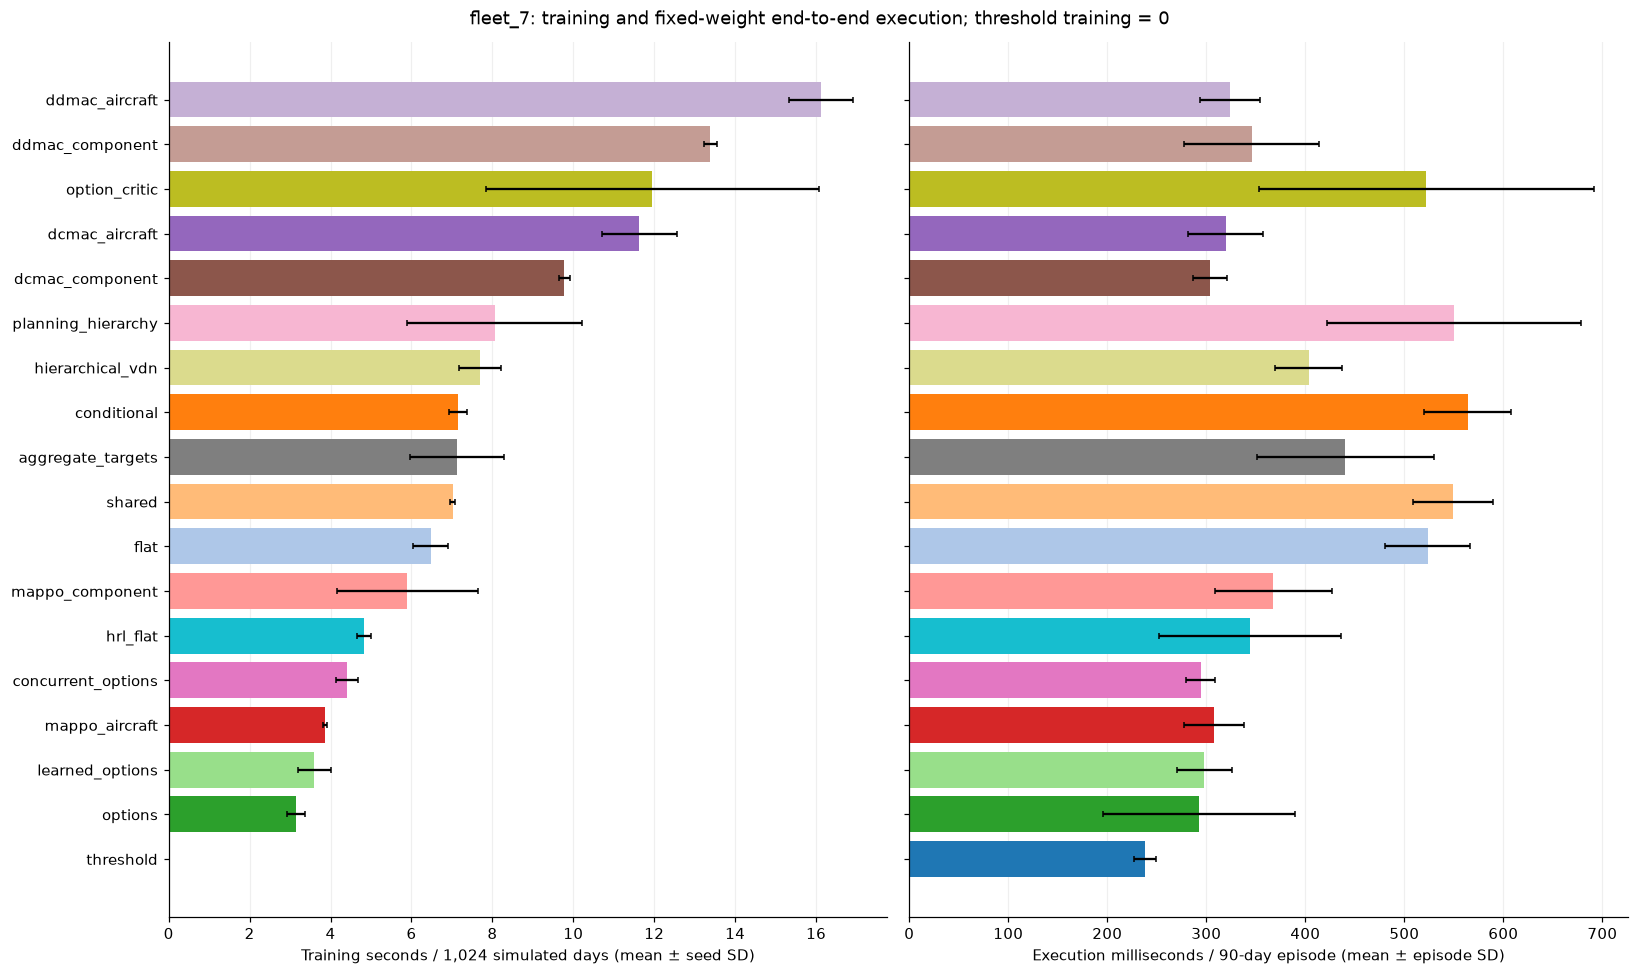

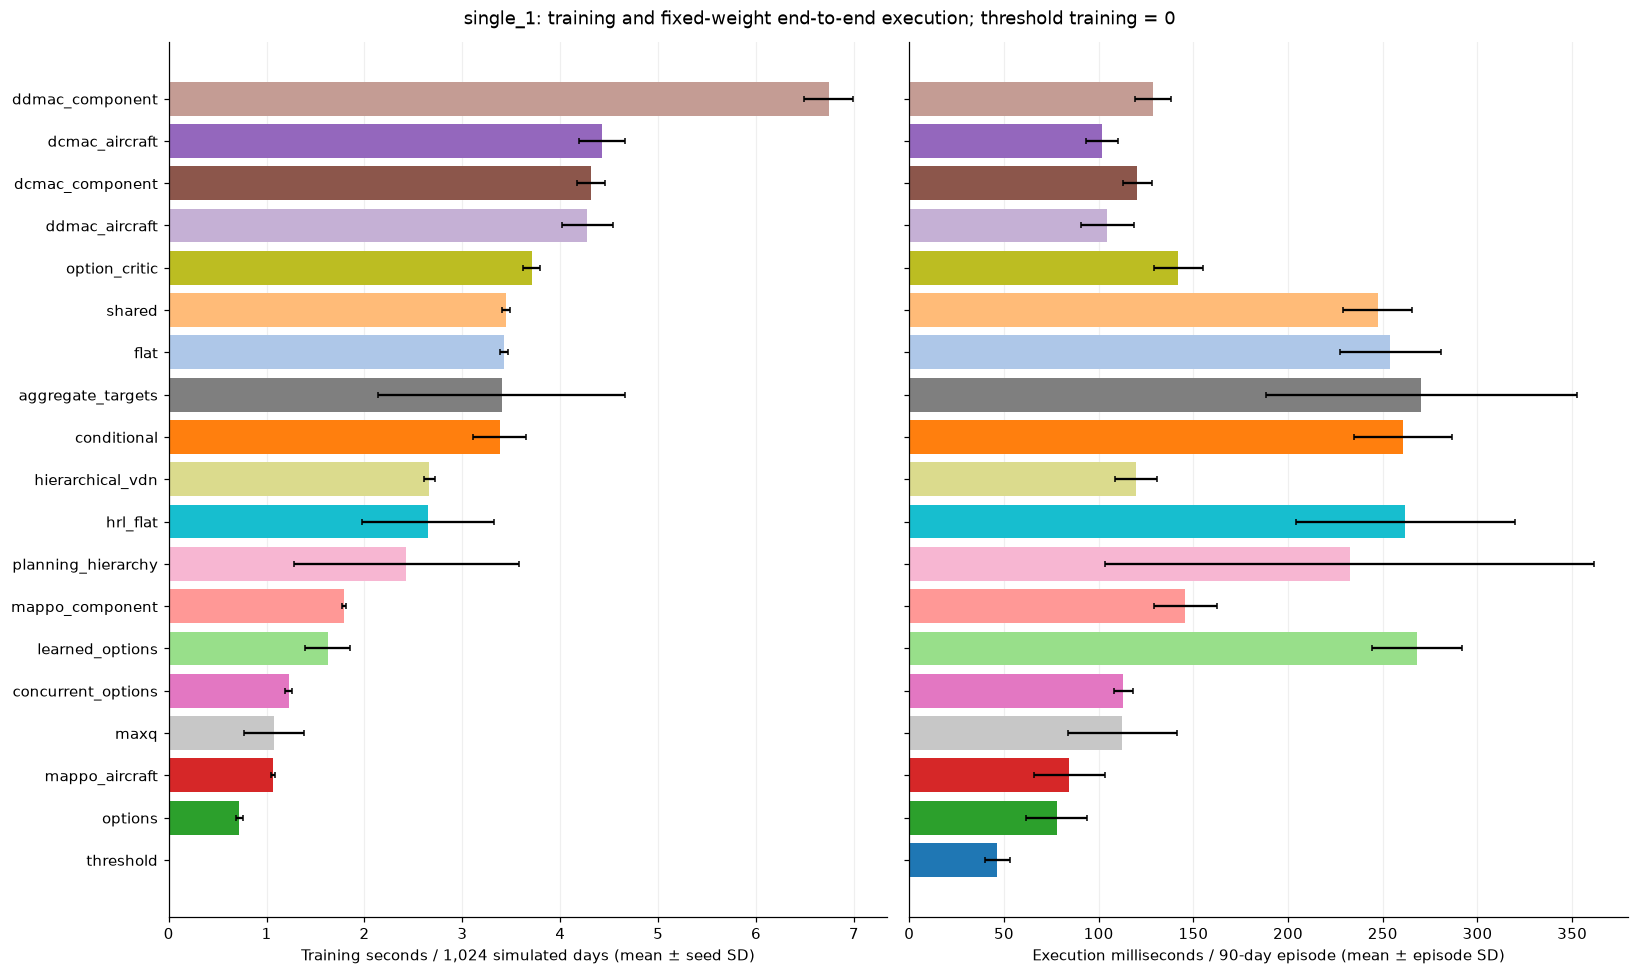

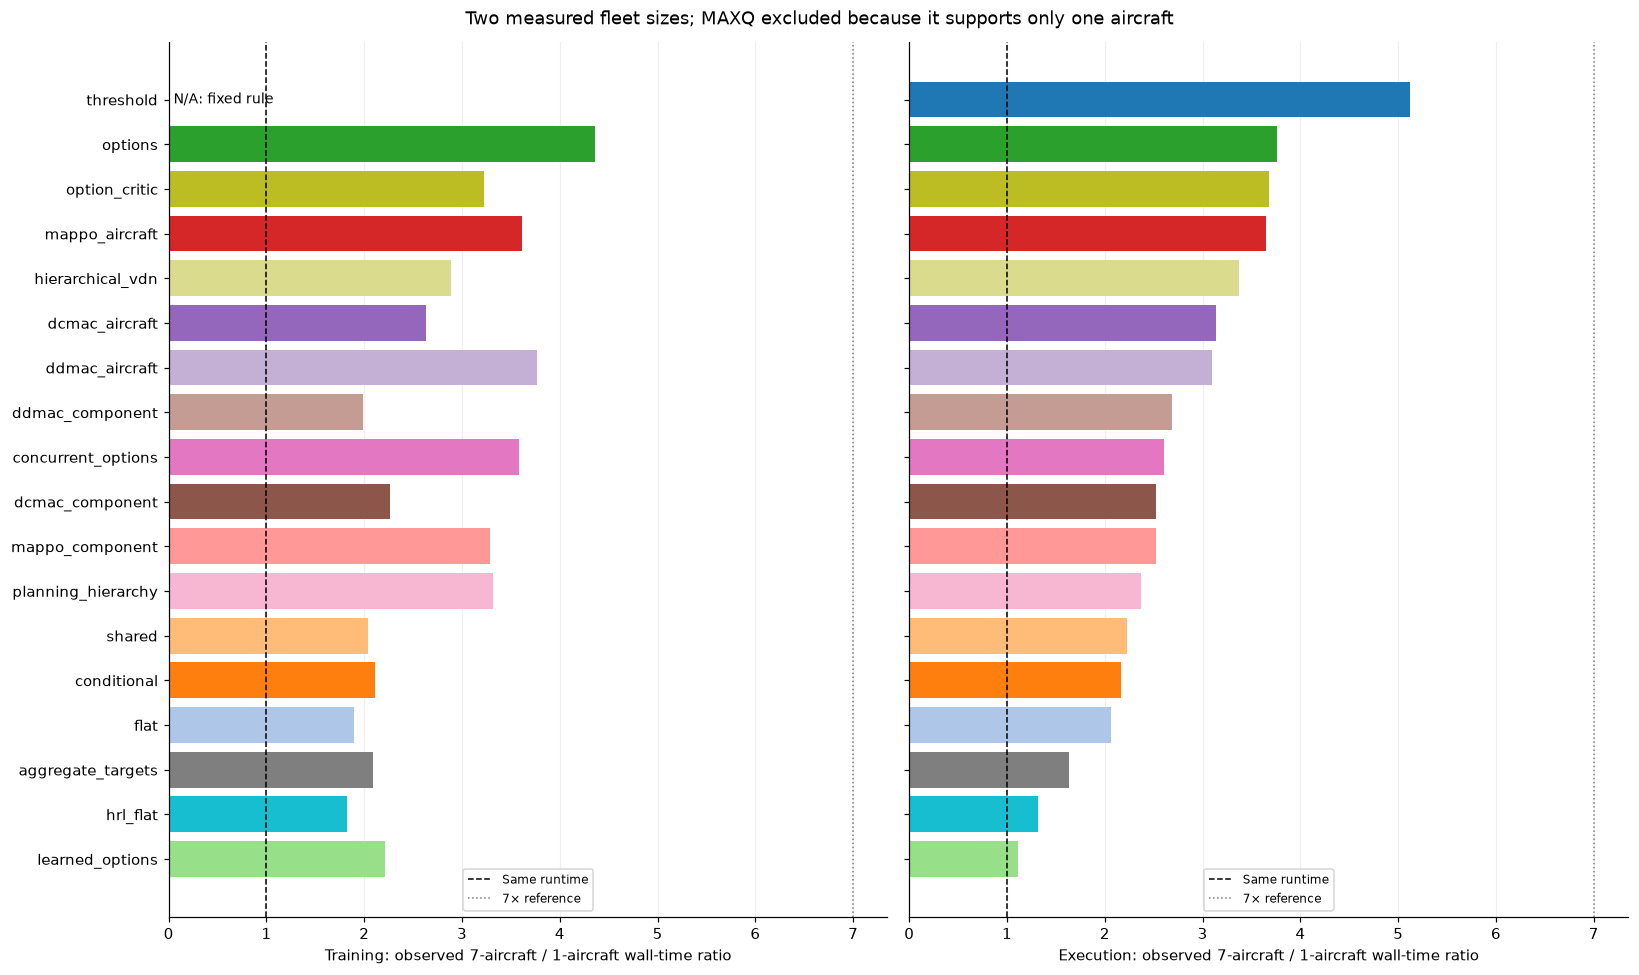

Threshold has no training ratio; execution ratios include the threshold rule.


In [9]:
runtime_columns = ['training_seconds', 'training_ms_per_simulated_day',
                   'training_ms_per_aircraft_day', 'execution_seconds',
                   'execution_seconds_per_episode', 'execution_ms_per_simulated_day',
                   'execution_ms_per_aircraft_day']
runtime_summary = execution_runs.groupby(['panel', 'method'])[runtime_columns].agg(['mean', 'std'])
runtime_summary.columns = [f'{metric}_{stat}' for metric, stat in runtime_summary.columns]
runtime_summary = runtime_summary.reset_index().fillna(0)
episode_timing = evaluation.groupby(['panel', 'method']).execution_seconds.agg(
    execution_episode_mean='mean', execution_episode_sd='std',
    execution_episode_p50='median', execution_episode_p95=lambda x: x.quantile(.95)).reset_index()
runtime_summary = runtime_summary.merge(episode_timing, on=['panel', 'method'])
runtime_summary['family'] = runtime_summary.method.map({**FAMILY, 'threshold': 'Fixed rule'})
runtime_summary.to_csv(RUN / 'data/runtime_summary.csv', index=False)
for panel in PANELS:
    display(Markdown(f'### {panel}: runtime per method'))
    display(runtime_summary[runtime_summary.panel.eq(panel)][['method',
        'training_seconds_mean', 'training_seconds_std', 'execution_episode_mean',
        'execution_episode_sd', 'execution_episode_p95', 'execution_ms_per_simulated_day_mean',
        'execution_ms_per_aircraft_day_mean']].sort_values('training_seconds_mean').rename(columns={
        'method': 'Method', 'training_seconds_mean': 'Train s', 'training_seconds_std': 'Train SD s',
        'execution_episode_mean': 'Exec s/episode', 'execution_episode_sd': 'Exec SD s',
        'execution_episode_p95': 'Exec P95 s', 'execution_ms_per_simulated_day_mean': 'Exec ms/day',
        'execution_ms_per_aircraft_day_mean': 'Exec ms/aircraft-day'}).round(4).reset_index(drop=True))

def runtime_bars(panel):
    data = runtime_summary[runtime_summary.panel.eq(panel)].sort_values('training_seconds_mean')
    fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
    axes[0].barh(data.method, data.training_seconds_mean, xerr=data.training_seconds_std,
                 color=[COLORS[m] for m in data.method], capsize=2)
    axes[0].set_xlabel(f'Training seconds / {TRAIN_DAYS:,} simulated days (mean ± seed SD)')
    axes[1].barh(data.method, 1000 * data.execution_episode_mean,
                 xerr=1000 * data.execution_episode_sd,
                 color=[COLORS[m] for m in data.method], capsize=2)
    axes[1].set_xlabel(f'Execution milliseconds / {HORIZON}-day episode (mean ± episode SD)')
    for ax in axes:
        ax.set_xlim(left=0)
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle(f'{panel}: training and fixed-weight end-to-end execution; threshold training = 0')
    fig.tight_layout()
    save_figure(fig, panel + '_training_execution_time')

runtime_bars('fleet_7')
runtime_bars('single_1')

scaling = runtime_summary.pivot(index='method', columns='panel',
    values=['training_seconds_mean', 'execution_episode_mean'])
common = scaling.dropna()
scaling_table = pd.DataFrame({
    'training_7_to_1_ratio': common['training_seconds_mean']['fleet_7'].div(
        common['training_seconds_mean']['single_1'].replace(0, np.nan)),
    'execution_7_to_1_ratio': common['execution_episode_mean']['fleet_7'].div(
        common['execution_episode_mean']['single_1'])}).sort_values('execution_7_to_1_ratio')
scaling_table.to_csv(RUN / 'data/runtime_fleet_size_ratio.csv')
fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
for ax, column, title in zip(axes, scaling_table.columns, ['Training', 'Execution']):
    ax.barh(scaling_table.index, scaling_table[column], color=[COLORS[m] for m in scaling_table.index])
    if column == 'training_7_to_1_ratio' and 'threshold' in scaling_table.index:
        ax.text(.05, list(scaling_table.index).index('threshold'), 'N/A: fixed rule', va='center', fontsize=9)
    ax.axvline(1, color='black', linewidth=1, linestyle='--', label='Same runtime')
    ax.axvline(7, color='gray', linewidth=1, linestyle=':', label='7× reference')
    ax.set_xlabel(f'{title}: observed 7-aircraft / 1-aircraft wall-time ratio')
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8)
fig.suptitle('Two measured fleet sizes; MAXQ excluded because it supports only one aircraft')
fig.tight_layout()
save_figure(fig, 'runtime_7_vs_1_aircraft')
print('Threshold has no training ratio; execution ratios include the threshold rule.')

## 7. Reload and execute a selected controller

For this demonstration, reload the best observed seven-aircraft learned controller
by mean evaluation return and execute it on additional seeds. These episodes are
kept separate from the ranking. Choosing it from the evaluation results makes it
a selection candidate; the additional episodes are a small follow-up, not a final
confirmation of superiority.

In [10]:
fleet_rank = summary[summary.panel.eq('fleet_7') & summary.method.ne('threshold')]
selected_method = fleet_rank.sort_values('return_mean', ascending=False).iloc[0].method
# Fix the training seed in advance rather than choosing the best individual checkpoint.
selected_seed = TRAIN_SEEDS[0]
checkpoint = RUN / 'checkpoints' / f'fleet_7__{selected_method}__seed{selected_seed}.pt'
loaded_cfg, loaded_method, selected_model = core.load_checkpoint(checkpoint)
demo_records, demo_timing = timed_evaluate(loaded_cfg, loaded_method, selected_model, seeds=[20000, 20001, 20002])
demo = pd.DataFrame(demo_records)
save_json(RUN / 'data/selected_controller_execution_timing.json', demo_timing)
demo.to_csv(RUN / 'data/selected_controller_execution.csv', index=False)
display(Markdown(f'**Reloaded controller:** `{selected_method}`, training seed `{selected_seed}`.'))
display(demo[['seed', 'return', 'availability', 'cost', 'flight_failures', 'replacements', 'execution_seconds']].round(3))

**Reloaded controller:** `hierarchical_vdn`, training seed `0`.

,seed,return,availability,cost,flight_failures,replacements,execution_seconds
0,20000,90.000,1.0,0.0,0.0,0.0,0.499
1,20001,90.000,1.0,0.0,0.0,0.0,0.506
2,20002,85.429,1.0,320.0,4.0,0.0,0.471


## 8. Results and interpretation

The following conclusions are generated from this execution's saved tables. They
are not hard-coded claims that an HRL or MARL method must win.

In [11]:
def best_row(panel, names):
    data = summary[summary.panel.eq(panel) & summary.method.isin(names)]
    return data.sort_values('return_mean', ascending=False).iloc[0]

fleet_best = best_row('fleet_7', ['threshold', *METHODS['fleet_7']])
best_marl = best_row('fleet_7', MARL)
best_hrl = best_row('fleet_7', HRL)
single_best = best_row('single_1', ['threshold', *ALL_METHODS])
single_ties = summary[summary.panel.eq('single_1') & np.isclose(summary.return_mean, single_best.return_mean, rtol=0, atol=1e-9)].method.tolist()
maxq = summary[(summary.panel == 'single_1') & (summary.method == 'maxq')].iloc[0]
baseline = summary[(summary.panel == 'fleet_7') & (summary.method == 'threshold')].iloc[0]
planning_delta = delta_summary.loc['planning_hierarchy', 'mean_delta_return']
planning_pair_signs = int((deltas['planning_hierarchy'] > 0).sum())
learned = fleet_rank.sort_values('return_mean', ascending=False)
gap = learned.iloc[0].return_mean - learned.iloc[1].return_mean
baseline_delta = learned.iloc[0].return_mean - baseline.return_mean
metric_winners = {}
for metric, ascending in [('availability_mean', False), ('cost_per_aircraft_day_mean', True),
                          ('flight_failures_mean', True)]:
    candidates = summary[summary.panel.eq('fleet_7')]
    optimum = candidates[metric].min() if ascending else candidates[metric].max()
    winners = candidates[np.isclose(candidates[metric], optimum)].method.tolist()
    metric_winners[metric] = f'all {len(winners)} methods ({optimum:g})' if len(winners) == len(candidates) else ', '.join(winners)
failure_total = int(evaluation[evaluation.panel.eq('fleet_7')].flight_failures.sum())
best_learned = learned.iloc[0]
availability_contribution = HORIZON * (best_learned.availability_mean - baseline.availability_mean)
cost_contribution = -HORIZON / 10 * (best_learned.cost_per_aircraft_day_mean - baseline.cost_per_aircraft_day_mean)
assert np.isclose(availability_contribution + cost_contribution, baseline_delta)

fleet_runtime = runtime_summary[runtime_summary.panel.eq('fleet_7')]
learned_runtime = fleet_runtime[fleet_runtime.method.ne('threshold')]
fastest_training = learned_runtime.sort_values('training_seconds_mean').iloc[0]
slowest_training = learned_runtime.sort_values('training_seconds_mean').iloc[-1]
fastest_execution = learned_runtime.sort_values('execution_episode_mean').iloc[0]
slowest_execution = learned_runtime.sort_values('execution_episode_mean').iloc[-1]
baseline_runtime = fleet_runtime[fleet_runtime.method.eq('threshold')].iloc[0]
selected_runtime = fleet_runtime[fleet_runtime.method.eq(selected_method)].iloc[0]
training_range_ratio = slowest_training.training_seconds_mean / fastest_training.training_seconds_mean
execution_range_ratio = slowest_execution.execution_episode_mean / fastest_execution.execution_episode_mean
scaling_min = scaling_table.execution_7_to_1_ratio.min()
scaling_max = scaling_table.execution_7_to_1_ratio.max()

conclusion = f'''### Observed outcome

- **Highest seven-aircraft mean return:** `{fleet_best.method}` ({fleet_best.return_mean:.2f}).
- **Best observed MARL method:** `{best_marl.method}` ({best_marl.return_mean:.2f}; training-seed SD {best_marl.return_std:.2f}).
- **Best observed HRL method:** `{best_hrl.method}` ({best_hrl.return_mean:.2f}; training-seed SD {best_hrl.return_std:.2f}).
- The top learned controller is **{baseline_delta:+.2f} return units relative to the threshold rule**. Its lead over the second learned controller is {gap:.2f}; this is descriptive, not a significance test.
- **One-aircraft result:** {len(single_ties)} methods tie at the highest mean return ({single_best.return_mean:.2f}); MAXQ ranks {int(maxq.rank_by_return)} of {len(ALL_METHODS)+1}, with return {maxq.return_mean:.2f}. This panel cannot establish fleet scalability.

### Does explicit hierarchy help in the closer comparison?

`planning_hierarchy - hrl_flat` is **{planning_delta:+.2f} mean return units**, positive in {planning_pair_signs}/{len(TRAIN_SEEDS)} paired training seeds. The two methods share the catalog, broker, information and duration accounting; network parameterization and size still differ. Other method comparisons also change decision authority, update rules or timing.

### What explains the scores?

Highest availability: **{metric_winners['availability_mean']}**. Lowest cost per aircraft-day: **{metric_winners['cost_per_aircraft_day_mean']}**. Fewest failed flights: **{metric_winners['flight_failures_mean']}**. Inspect these alongside replacements and training curves: a return lead can arise from a different availability/maintenance trade-off, rather than a universally better maintenance policy.

The top learned controller's return difference from the threshold rule decomposes exactly into **{availability_contribution:+.2f} units from flown availability** and **{cost_contribution:+.2f} units from total cost**. This follows the simulator identity `episode return = horizon * availability - cost / (10 * aircraft)`; it is an accounting explanation rather than a causal architecture claim.

The leading learned controller averages **{best_learned.replacements_mean:.2f} replacements and {best_learned.availability_mean:.1%} availability**. The leading MARL controller averages **{best_marl.replacements_mean:.2f} replacements and {best_marl.availability_mean:.1%} availability**; the leading HRL controller averages **{best_hrl.replacements_mean:.2f} replacements and {best_hrl.availability_mean:.1%} availability**. These observed maintenance/grounding differences help explain the return differences. Different categorical action spaces and limited training are possible contributors that this experiment does not isolate.

The finite **{HORIZON}-day horizon**, initially high health, and absence of a terminal charge for remaining degradation can favor policies that defer maintenance beyond the evaluated episode. A score close to {HORIZON} approaches this environment's return ceiling. Inspect failures and replacement counts, and extend the horizon or test more degraded initial states consistently across methods before interpreting such a score as a strong lifetime maintenance policy.

### Training and execution duration

- **Fastest trained fleet method:** `{fastest_training.method}`, {fastest_training.training_seconds_mean:.2f} s per {TRAIN_DAYS:,} simulated days. Slowest: `{slowest_training.method}`, {slowest_training.training_seconds_mean:.2f} s ({training_range_ratio:.2f}× the fastest).
- **Fastest learned fleet controller at execution:** `{fastest_execution.method}`, {1000*fastest_execution.execution_episode_mean:.1f} ms per {HORIZON}-day episode. Slowest: `{slowest_execution.method}`, {1000*slowest_execution.execution_episode_mean:.1f} ms ({execution_range_ratio:.2f}× the fastest).
- **Fixed threshold rule:** no training; {1000*baseline_runtime.execution_episode_mean:.1f} ms per episode. Its execution time is still measured and plotted.
- **Return-selected controller `{selected_method}`:** training {selected_runtime.training_seconds_mean:.2f} s; execution {1000*selected_runtime.execution_episode_mean:.1f} ms per episode, or {selected_runtime.execution_ms_per_simulated_day_mean:.3f} ms per simulated day. Return leadership and runtime leadership are separate outcomes.
- Across shared methods, the observed seven-to-one-aircraft execution multiplier ranges from {scaling_min:.2f}× to {scaling_max:.2f}×. This combines controller, broker and simulator costs and is not an asymptotic scaling law.

Training uses the same simulation-day budget, but numbers of updates and effective decisions differ. A shorter training time does not establish better sample efficiency or convergence. Execution bars summarize episode timing variability, while training bars summarize trained-seed variability. CPU load, implementation details and the small network sizes affect these measurements. Before sizing the large model, repeat at the intended aircraft/resource counts and hardware; these timings do not isolate pure neural forward-pass latency.

### Limits and next decision

This run uses **{TRAIN_DAYS:,} simulated training days per seed, {len(TRAIN_SEEDS)} training seeds and {len(EVAL_SEEDS)} held-out episodes per trained model**. Error bars show training-seed variation, not confidence intervals or all evaluation uncertainty. Only {failure_total} failed-flight occurrences were recorded across the seven-aircraft evaluation rows; these rows reuse scenarios across methods, so that total is not an independent estimate of a real-world failure rate. Zero observed failures leave failure-risk performance unresolved in this pilot.

The current candidate for a longer fleet experiment is `{selected_method}` by observed learned-policy return. Extend the budget and seed count and check performance on fresh evaluation scenarios before claiming a winner. All controllers use the current synthetic physical model; no hot-weather, dust, salt or flight-hour upgrade was introduced by this notebook. Results reflect the method implementations in this repository, not a ranking of the original papers' algorithms.
'''
display(Markdown(conclusion))
(RUN / 'results_interpretation.md').write_text(conclusion, encoding='utf-8')
manifest['status'] = 'complete'
manifest['completed_training_runs'] = len(runs)
manifest['evaluation_rows'] = len(evaluation)
manifest['selected_fleet_controller'] = selected_method
manifest['runtime_note'] = 'Sequential CPU training and fixed-weight end-to-end evaluation; warm-ups/loading/saving/plotting excluded from execution timing.'
manifest['execution_timing_rows'] = len(execution_runs)
save_json(RUN / 'manifest.json', manifest)
save_json(RUN / 'verification.json', {'all_methods_covered': set(evaluation.method) == {'threshold', *ALL_METHODS},
    'all_checkpoint_reloads_verified': bool(runs.reload_verified.all()),
    'training_runs': len(runs), 'evaluation_rows': len(evaluation),
    'no_duplicate_evaluation_keys': True, 'all_returns_finite': True,
    'all_execution_times_positive': bool(evaluation.execution_seconds.gt(0).all()),
    'execution_blocks': len(execution_runs), 'runtime_summary_rows': len(runtime_summary),
    'runtime_figure_panels': ['fleet_7', 'single_1', 'seven_vs_one_ratio'],
    'comparison_figure_panels': ['fleet_7', 'single_1'], 'core_sha256': SOURCE_HASH})
print('Saved:', RUN.relative_to(PROJECT))
print('Tables: data/ | Figures: plots/ | Local weights: checkpoints/ | Local logs: training_logs/')

### Observed outcome

- **Highest seven-aircraft mean return:** `hierarchical_vdn` (89.83).
- **Best observed MARL method:** `mappo_aircraft` (46.62; training-seed SD 0.42).
- **Best observed HRL method:** `hierarchical_vdn` (89.83; training-seed SD 0.00).
- The top learned controller is **+29.16 return units relative to the threshold rule**. Its lead over the second learned controller is 0.02; this is descriptive, not a significance test.
- **One-aircraft result:** 16 methods tie at the highest mean return (90.00); MAXQ ranks 1 of 19, with return 90.00. This panel cannot establish fleet scalability.

### Does explicit hierarchy help in the closer comparison?

`planning_hierarchy - hrl_flat` is **+1.06 mean return units**, positive in 1/3 paired training seeds. The two methods share the catalog, broker, information and duration accounting; network parameterization and size still differ. Other method comparisons also change decision authority, update rules or timing.

### What explains the scores?

Highest availability: **hierarchical_vdn, conditional**. Lowest cost per aircraft-day: **hierarchical_vdn**. Fewest failed flights: **all 18 methods (0)**. Inspect these alongside replacements and training curves: a return lead can arise from a different availability/maintenance trade-off, rather than a universally better maintenance policy.

The top learned controller's return difference from the threshold rule decomposes exactly into **+16.53 units from flown availability** and **+12.63 units from total cost**. This follows the simulator identity `episode return = horizon * availability - cost / (10 * aircraft)`; it is an accounting explanation rather than a causal architecture claim.

The leading learned controller averages **0.05 replacements and 99.9% availability**. The leading MARL controller averages **41.22 replacements and 71.4% availability**; the leading HRL controller averages **0.05 replacements and 99.9% availability**. These observed maintenance/grounding differences help explain the return differences. Different categorical action spaces and limited training are possible contributors that this experiment does not isolate.

The finite **90-day horizon**, initially high health, and absence of a terminal charge for remaining degradation can favor policies that defer maintenance beyond the evaluated episode. A score close to 90 approaches this environment's return ceiling. Inspect failures and replacement counts, and extend the horizon or test more degraded initial states consistently across methods before interpreting such a score as a strong lifetime maintenance policy.

### Training and execution duration

- **Fastest trained fleet method:** `options`, 3.14 s per 1,024 simulated days. Slowest: `ddmac_aircraft`, 16.12 s (5.13× the fastest).
- **Fastest learned fleet controller at execution:** `options`, 292.4 ms per 90-day episode. Slowest: `conditional`, 564.0 ms (1.93× the fastest).
- **Fixed threshold rule:** no training; 238.0 ms per episode. Its execution time is still measured and plotted.
- **Return-selected controller `hierarchical_vdn`:** training 7.69 s; execution 403.4 ms per episode, or 4.482 ms per simulated day. Return leadership and runtime leadership are separate outcomes.
- Across shared methods, the observed seven-to-one-aircraft execution multiplier ranges from 1.11× to 5.12×. This combines controller, broker and simulator costs and is not an asymptotic scaling law.

Training uses the same simulation-day budget, but numbers of updates and effective decisions differ. A shorter training time does not establish better sample efficiency or convergence. Execution bars summarize episode timing variability, while training bars summarize trained-seed variability. CPU load, implementation details and the small network sizes affect these measurements. Before sizing the large model, repeat at the intended aircraft/resource counts and hardware; these timings do not isolate pure neural forward-pass latency.

### Limits and next decision

This run uses **1,024 simulated training days per seed, 3 training seeds and 20 held-out episodes per trained model**. Error bars show training-seed variation, not confidence intervals or all evaluation uncertainty. Only 0 failed-flight occurrences were recorded across the seven-aircraft evaluation rows; these rows reuse scenarios across methods, so that total is not an independent estimate of a real-world failure rate. Zero observed failures leave failure-risk performance unresolved in this pilot.

The current candidate for a longer fleet experiment is `hierarchical_vdn` by observed learned-policy return. Extend the budget and seed count and check performance on fresh evaluation scenarios before claiming a winner. All controllers use the current synthetic physical model; no hot-weather, dust, salt or flight-hour upgrade was introduced by this notebook. Results reflect the method implementations in this repository, not a ranking of the original papers' algorithms.


Saved: results\presentation_20261026T154304Z
Tables: data/ | Figures: plots/ | Local weights: checkpoints/ | Local logs: training_logs/
